In [1]:
import pandas as pd
url = "../data/clean/bookworms_cleaned_data_file.csv"
df = pd.read_csv(url, dtype={"isbn": str, "isbn13": str})
#making sure isbn and isbn13 are imported as str
df.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher,publication_year
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652.0,2095690,27591,9/16/2006,Scholastic Inc.,2006
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870.0,2153167,29221,9/1/2004,Scholastic Inc.,2004
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352.0,6333,244,11/1/2003,Scholastic,2003
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435.0,2339585,36325,5/1/2004,Scholastic Inc.,2004
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690.0,41428,164,9/13/2004,Scholastic,2004


In [2]:
# H1 - Ratings and popularity: Books with more Goodreads ratings tend to have higher average ratings.

rated_books = df.dropna(subset=["average_rating"]) #checking only this column for non-values
has_ratings = rated_books["ratings_count"] > 0
rated_books = rated_books[has_ratings]

print("Total records:", len(df))
print("Records with ratings:", len(rated_books))
#There are 11042 books with ratings above 0

# Finding the middle value of the rating counts
median_count = rated_books["ratings_count"].median()

# Divide editions into two groups
lower_group = rated_books[rated_books["ratings_count"] <= median_count]
higher_group = rated_books[rated_books["ratings_count"] > median_count]

# Compare their average scores
print("Rating-count cutoff:", median_count)

print("\nLower-count group:", len(lower_group), "editions")
print("Mean score:", lower_group["average_rating"].mean().round(3))

print("\nHigher-count group:", len(higher_group), "editions")
print("Mean score:", higher_group["average_rating"].mean().round(3))

Total records: 11123
Records with ratings: 11042
Rating-count cutoff: 764.5

Lower-count group: 5521 editions
Mean score: 3.923

Higher-count group: 5521 editions
Mean score: 3.963


# Conclusion H1

Editions with more Goodreads ratings had a slightly higher mean score (3.963) than those with fewer ratings (3.923).
The difference was only 0.04 points out of 5, providing limited descriptive support for H1. 
For Bookworms, rating count alone offers little guidance on reader satisfaction, so recommendations should consider
both average rating and number of ratings.

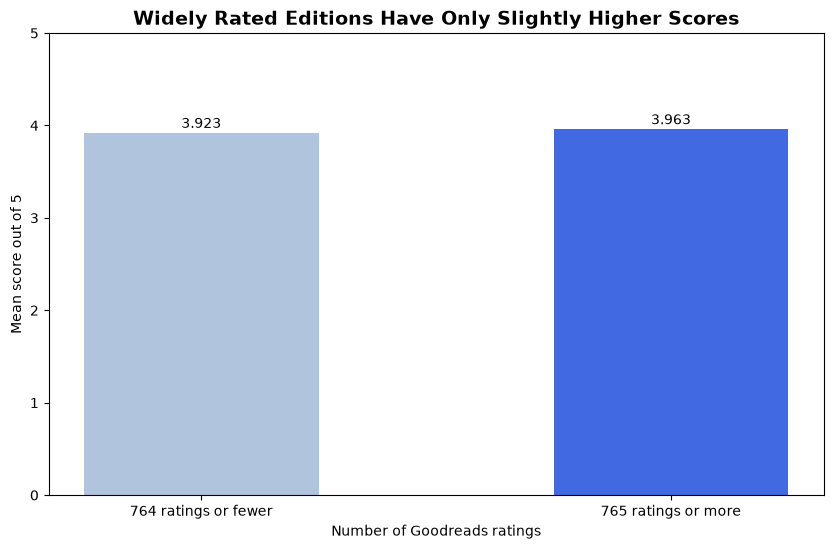

In [3]:
import matplotlib.pyplot as plt

# For the graph
labels = ["764 ratings or fewer", "765 ratings or more"]

scores = [lower_group["average_rating"].mean(), higher_group["average_rating"].mean()]

# Create the bar chart
plt.figure(figsize=(10, 6))
plt.bar(labels, scores, color=["lightsteelblue", "royalblue"], width=0.5)

# Show each mean above its bar
for i, score in enumerate(scores):
    plt.text(i, score + 0.05, f"{score:.3f}", ha="center")

plt.title(
    "Widely Rated Editions Have Only Slightly Higher Scores",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Number of Goodreads ratings")
plt.ylabel("Mean score out of 5")

# Show the full rating scale and saving the graph
plt.ylim(0, 5)

plt.savefig("h1_ratings_and_popularity.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
# H2 - Author consistency: Some authors with multiple books consistently receive higher ratings than the overall book population.

rated_books["authors"].value_counts().head(20) #20 most frequent authors

authors
Stephen King                   40
P.G. Wodehouse                 40
Rumiko Takahashi               38
Orson Scott Card               35
Agatha Christie                33
Piers Anthony                  30
Mercedes Lackey                29
Sandra Brown                   29
Dick Francis                   28
Margaret Weis/Tracy Hickman    23
Terry Pratchett                23
James Patterson                23
Laurell K. Hamilton            23
Bill Bryson                    21
Gordon Korman                  21
Janet Evanovich                21
Dan Simmons                    21
Alan Dean Foster               21
Gabriel García Márquez         20
Dean Koontz                    20
Name: count, dtype: int64

In [5]:
author_summary = rated_books.groupby("authors").agg(
    edition_count=("bookID", "count"), #how many books belong to that author
    median_rating=("average_rating", "median"), #the middle score among those editions
    total_ratings=("ratings_count", "sum") #number of ratings across those records
)

author_summary.sort_values("edition_count", ascending=False).head(20) #top 20 authors with the most books

,edition_count,median_rating,total_ratings
authors,,,
P.G. Wodehouse,40,4.165,96053
Stephen King,40,3.965,2985634
Rumiko Takahashi,38,4.235,45292
Orson Scott Card,35,3.840,656554
Agatha Christie,33,3.970,1599571
Piers Anthony,30,3.755,93428
Sandra Brown,29,3.630,118480
Mercedes Lackey,29,4.030,310832
Dick Francis,28,3.985,82544


In [6]:
# Defining a benchmark for comparison
catalogue_median = rated_books["average_rating"].median()
print("Catalogue median rating:", catalogue_median)

Catalogue median rating: 3.96


In [7]:
# authors with median scores above the benchmark

authors_above_catalogue = author_summary[
    (author_summary["edition_count"] >= 3) & #at least 3 books
    (author_summary["total_ratings"] >= 1000) & #at least 1000 ratings
    (author_summary["median_rating"] > catalogue_median) #median above benchmark
]

authors_above_catalogue.sort_values("median_rating", ascending=False).head(20)

,edition_count,median_rating,total_ratings
authors,,,
Bill Watterson,7,4.710,144799
Hayao Miyazaki/Matt Thorn/Kaori Inoue/Joe Yamazaki/Walden Wong/Izumi Evers,3,4.610,5396
Hiromu Arakawa/Akira Watanabe,12,4.570,229591
J.K. Rowling/Mary GrandPré,6,4.525,8923980
Jude Fisher,3,4.500,1698
J.R.R. Tolkien,17,4.500,4776638
J.K. Rowling,11,4.490,75044
Kyoko Hikawa/Yuko Sawada/Freeman Wong,3,4.480,2792
Warren Ellis/Darick Robertson/Rodney Ramos,4,4.455,43962


In [8]:
# how consistently do their editions exceed that benchmark

# Copying rated records for the H2 analysis
h2_books = rated_books.copy()

# middle rating across all rated editions
catalogue_median = h2_books["average_rating"].median()

print("Catalogue median:", catalogue_median)

# True = rating scores above the catalogue median; False = rating scores at or below the median
h2_books["above_catalogue"] = (h2_books["average_rating"] > catalogue_median)

# Inspect examples of the comparison
h2_books[["authors", "average_rating", "above_catalogue"]].head(10)

Catalogue median: 3.96


,authors,average_rating,above_catalogue
0,J.K. Rowling/Mary GrandPré,4.57,True
1,J.K. Rowling/Mary GrandPré,4.49,True
2,J.K. Rowling,4.42,True
3,J.K. Rowling/Mary GrandPré,4.56,True
4,J.K. Rowling/Mary GrandPré,4.78,True
5,W. Frederick Zimmerman,3.74,False
6,J.K. Rowling,4.73,True
7,Douglas Adams,4.38,True
8,Douglas Adams,4.38,True
9,Douglas Adams,4.22,True


In [9]:
# Group by author, consider consistent when above benchmark 3 out of 4 times (75%)

consistency = (h2_books.groupby("authors")["above_catalogue"].mean() * 100).round(2)

author_summary["percent_above_catalogue"] = consistency

# Show the same top 20 by edition count, now including consistency
author_summary.sort_values("edition_count", ascending=False).head(20)

,edition_count,median_rating,total_ratings,percent_above_catalogue
authors,,,,
P.G. Wodehouse,40,4.165,96053,85.00
Stephen King,40,3.965,2985634,50.00
Rumiko Takahashi,38,4.235,45292,97.37
Orson Scott Card,35,3.840,656554,17.14
Agatha Christie,33,3.970,1599571,51.52
Piers Anthony,30,3.755,93428,10.00
Sandra Brown,29,3.630,118480,24.14
Mercedes Lackey,29,4.030,310832,72.41
Dick Francis,28,3.985,82544,60.71


In [10]:
# Filtering author entries
consistent_authors = author_summary[
    (author_summary["edition_count"] >= 3) &          # At least 3 editions
    (author_summary["total_ratings"] >= 1000) &       # At least 1000 ratings
    (author_summary["median_rating"] > catalogue_median) &
    (author_summary["percent_above_catalogue"] >= 75) # 75% score above the benchmark
]

print("Qualifying author entries:", len(consistent_authors))

consistent_authors.sort_values("median_rating", ascending=False).head(20).round(2)

Qualifying author entries: 214


,edition_count,median_rating,total_ratings,percent_above_catalogue
authors,,,,
Bill Watterson,7,4.71,144799,100.00
Hayao Miyazaki/Matt Thorn/Kaori Inoue/Joe Yamazaki/Walden Wong/Izumi Evers,3,4.61,5396,100.00
Hiromu Arakawa/Akira Watanabe,12,4.57,229591,100.00
J.K. Rowling/Mary GrandPré,6,4.53,8923980,100.00
J.R.R. Tolkien,17,4.50,4776638,100.00
J.K. Rowling,11,4.49,75044,100.00
Kyoko Hikawa/Yuko Sawada/Freeman Wong,3,4.48,2792,100.00
Warren Ellis/Darick Robertson/Rodney Ramos,4,4.46,43962,100.00
Karen Kingsbury/Gary Smalley,5,4.45,81932,100.00


## Conclusion H2

Several credited author entries consistently score above the catalogue median of 3.96.
Bill Watterson has a median rating of 4.71 across 7 editions, J.K. Rowling has 4.49 across 25 and J.R.R. Tolkien has 4.44 across 25. All rated editions for Watterson and Rowling scored above the catalogue median of 3.96. For Tolkien, 24 of 25 editions (96%) scored above it. These authors are candidates for further review for Bookworms recommendations.

Different editions can represent the same work. Joint author credits were assessed together.

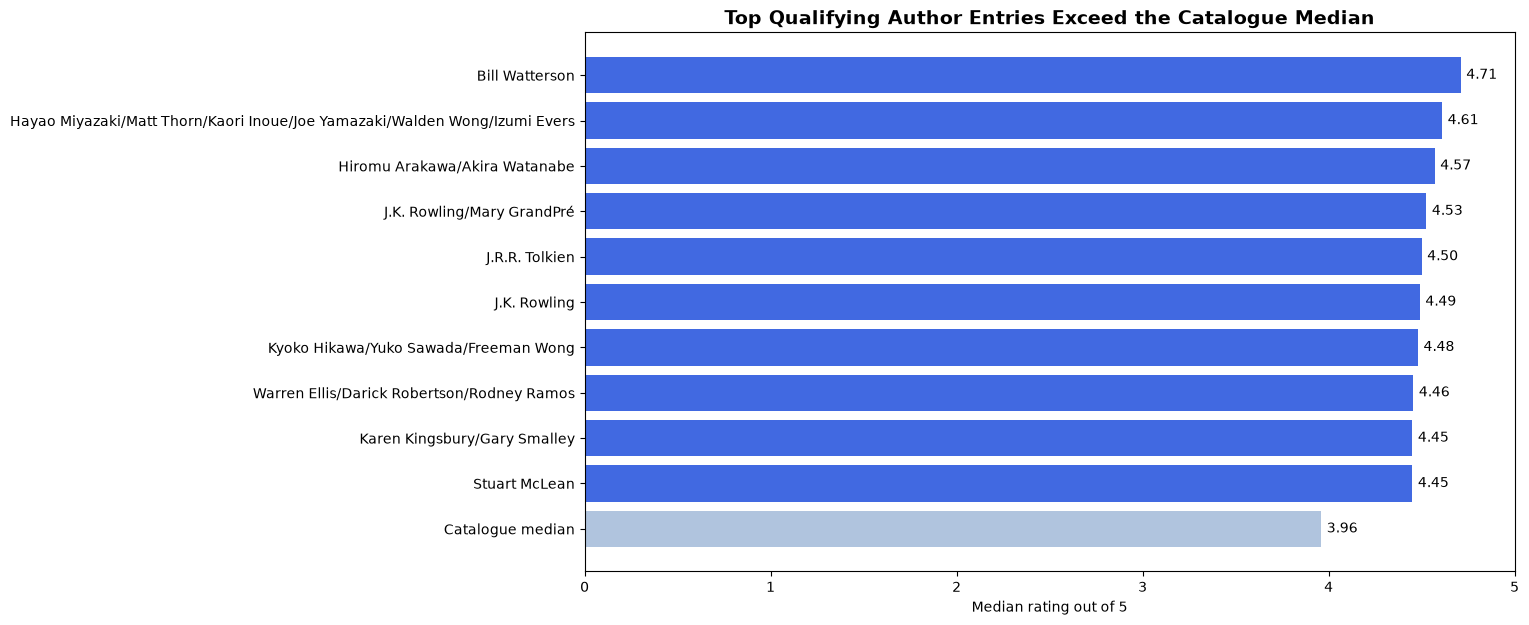

In [11]:
# Select the 10 qualifying entries with the highest median scores
top_authors = consistent_authors.sort_values("median_rating", ascending=False).head(10)

top_authors = top_authors.sort_values("median_rating")

labels = ["Catalogue median"] + top_authors.index.tolist()
scores = [catalogue_median] + top_authors["median_rating"].tolist()

colors = ["lightsteelblue"] + ["royalblue"] * len(top_authors)

plt.figure(figsize=(12, 7))
plt.barh(labels, scores, color=colors)

# Display each median score beside its bar
for i, score in enumerate(scores):
    plt.text(score + 0.03, i, f"{score:.2f}", va="center")

plt.title(
    "Top Qualifying Author Entries Exceed the Catalogue Median",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Median rating out of 5")
plt.xlim(0, 5)

plt.savefig("h2_author_consistency.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
# H3: Book length: Longer books tend to receive different average ratings than shorter books.

# Exclude missing page counts and records with 1–2 pages (audiobooks)
h3_books = rated_books[rated_books["num_pages"] > 2]
pages = h3_books["num_pages"]

# Separate into three groups based on page count
short_editions = h3_books[pages <= 100] #books up to 100 pages long
medium_editions = h3_books[(pages > 100) & (pages <= 400)] #books between 101 and 400 pages
long_editions = h3_books[pages > 400] #more than 400 pages

# Calculate the mean for each group
h3_summary = pd.DataFrame({
    "Page range": ["3–100", "101–400", "Over 400"],
    "Editions": [len(short_editions), len(medium_editions), len(long_editions)],
    "Mean score": [
        short_editions["average_rating"].mean(),
        medium_editions["average_rating"].mean(),
        long_editions["average_rating"].mean()
    ]})

h3_summary.round(3)

,Page range,Editions,Mean score
0,3–100,921,3.968
1,101–400,7034,3.907
2,Over 400,2988,4.021


## Conclusion H3

Average ratings varied slightly by page count. Editions over 400 pages had the highest average rating (4.021), followed by editions of 3–100 pages (3.968) and 101–400 pages (3.907). The difference between the longest and shortest groups was only 0.053 points out of 5, and the middle group scored lowest. These results provide limited descriptive support for H3.
    
Bookworms can use page count to curate collections such as Short Reads, while using ratings directly to assess reader satisfaction.

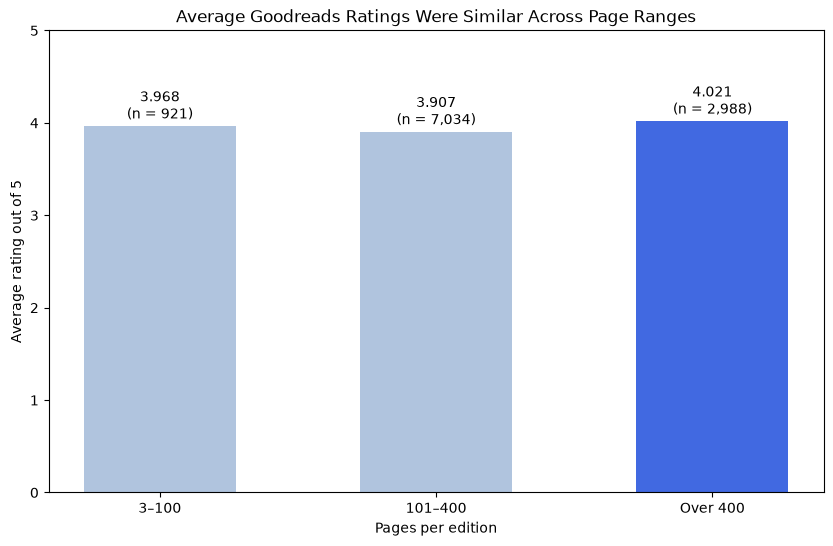

In [13]:
# H3 chart
page_ranges = h3_summary["Page range"]
mean_scores = h3_summary["Mean score"]
edition_counts = h3_summary["Editions"]

plt.figure(figsize=(10, 6))
plt.bar(
    page_ranges,
    mean_scores,
    color=["lightsteelblue", "lightsteelblue", "royalblue"],
    width=0.55
)

# Show the mean score and edition count
for i, (score, count) in enumerate(zip(mean_scores, edition_counts)):
    plt.text(i, score + 0.08, f"{score:.3f}\n(n = {count:,})", ha="center")

plt.title("Average Goodreads Ratings Were Similar Across Page Ranges")
plt.xlabel("Pages per edition")
plt.ylabel("Average rating out of 5")
plt.ylim(0, 5)

# Save the chart
plt.savefig("h3_book_length.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
# H4 - Publication period: Average ratings and Goodreads engagement differ across publication periods.

print("Oldest book:", rated_books["publication_year"].min())
print("Most recent book:", rated_books["publication_year"].max())

Oldest book: 1900
Most recent book: 2020


In [15]:
# Make a copy for H4
h4_books = rated_books.copy()

# Turn each publication year into its decade
def get_decade(year):
    # Check from newest to oldest so the first match is the right decade
    if year >= 2020:
        return "2020s"
    elif year >= 2010:
        return "2010s"
    elif year >= 2000:
        return "2000s"
    elif year >= 1990:
        return "1990s"
    elif year >= 1980:
        return "1980s"
    elif year >= 1970:
        return "1970s"
    elif year >= 1960:
        return "1960s"
    elif year >= 1950:
        return "1950s"
    elif year >= 1940:
        return "1940s"
    elif year >= 1930:
        return "1930s"
    elif year >= 1920:
        return "1920s"
    elif year >= 1910:
        return "1910s"
    elif year >= 1900:
        return "1900s"
    else:
        return "Before 1900"

# Apply the function to each year and store the returned labels
h4_books["decade"] = h4_books["publication_year"].apply(get_decade)

# Check the new column alongside the original year
h4_books[["publication_year", "decade"]].head(10)

,publication_year,decade
0,2006,2000s
1,2004,2000s
2,2003,2000s
3,2004,2000s
4,2004,2000s
5,2005,2000s
6,2005,2000s
7,2005,2000s
8,2002,2000s
9,2004,2000s


In [16]:
# Compare scores and engagement across decades
h4_summary = h4_books.groupby("decade").agg(
    edition_count=("bookID", "count"), #how many books that decade
    mean_score=("average_rating", "mean"), #avg rating of the decade
    median_rating_count=("ratings_count", "median") #how many ratings the middle books received
)

h4_summary.round(3)

,edition_count,mean_score,median_rating_count
decade,,,
1900s,1,3.880,332.0
1910s,3,4.077,111.0
1920s,7,4.120,38.0
1930s,2,3.190,9.5
1940s,6,3.858,549.0
1950s,29,3.991,865.0
1960s,73,3.959,148.0
1970s,203,3.960,226.0
1980s,617,3.979,311.0


# Conclusion H4

Goodreads scores were similar across the five publication decades with at least 100 rated editions. Mean scores ranged from 3.935 to 3.981 out of 5. 
Engagement varied more: the median edition received 226 ratings in the 1970s, 641 in the 1990s, and 911 in the 2000s, before falling to 775 in the 2010s. 

Publication decade showed clearer differences in how many ratings editions received than in how highly readers scored them.

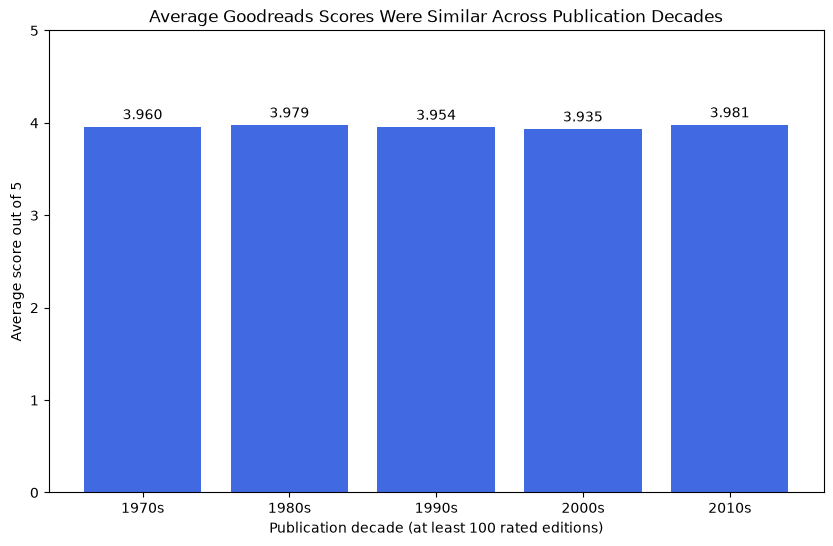

In [17]:
# Select decades with at least 100 rated editions
h4_chart = h4_summary[h4_summary["edition_count"] >= 100]

#Average score
plt.figure(figsize=(10, 6))
plt.bar(h4_chart.index, h4_chart["mean_score"], color="royalblue")

for i, score in enumerate(h4_chart["mean_score"]):
    plt.text(i, score + 0.08, f"{score:.3f}", ha="center")

plt.title("Average Goodreads Scores Were Similar Across Publication Decades")
plt.xlabel("Publication decade (at least 100 rated editions)")
plt.ylabel("Average score out of 5")
plt.ylim(0, 5)
plt.savefig("h4_mean_scores_by_decade.png", dpi=200, bbox_inches="tight")
plt.show()

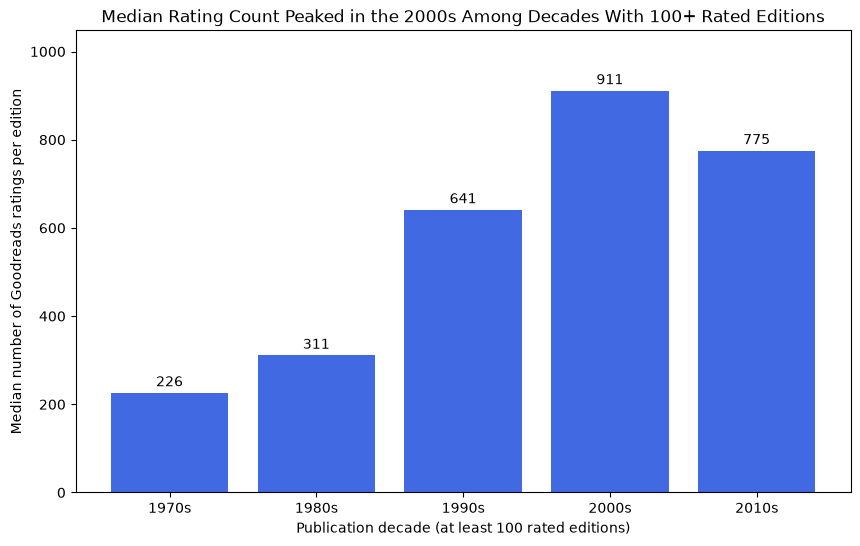

In [18]:
# Median number of ratings
plt.figure(figsize=(10, 6))
plt.bar(h4_chart.index, h4_chart["median_rating_count"], color="royalblue")

for i, count in enumerate(h4_chart["median_rating_count"]):
    plt.text(i, count + 15, f"{count:,.0f}", ha="center")

plt.title("Median Rating Count Peaked in the 2000s Among Decades With 100+ Rated Editions")
plt.xlabel("Publication decade (at least 100 rated editions)")
plt.ylabel("Median number of Goodreads ratings per edition")
plt.ylim(0, h4_chart["median_rating_count"].max() * 1.15)
plt.savefig("h4_rating_counts_by_decade.png", dpi=200, bbox_inches="tight")
plt.show()

In [19]:
# Which books should Bookworms prioritize for recommendations? 

# Editions with more Goodreads ratings scored only slightly higher on average. "Popular Favourites" therefore combines a 
# high score with a high rating count. "Hidden-Gems" highlights editions with very high scores and fewer ratings.

# Average ratings were similar across page ranges and well-represented decades. We use page count to help readers
# find shorter editions and publication year to help them discover older editions.

# All four collections are limited to English-language editions. An edition can qualify for more than one collection.

# Popular Favourites — average rating of at least 4.0 and at least 10,000 ratings.
# Recommended Short Reads — average rating of at least 4.0, at least 500 ratings, and 3–100 pages.
# Hidden-Gems — average rating of at least 4.5 and 100–999 ratings.
# Popular Classics — average rating of at least 4.0 and edition publication year before 1976.

english = df["language_code"] == "eng" #focusing on eng
df["collections"] = "" #new column

# Popular Favourites
popular_fav = (
    english 
    & (df["average_rating"] >= 4.0) #books with at least 4.0 avg
    & (df["ratings_count"] >= 10000) #at least 10000 ratings
)

df.loc[popular_fav, "collections"] += "Popular Favourites / "
print("Popular Favourites:", popular_fav.sum())

# Recommended Short Reads

short_reads = (
    english
    & (df["average_rating"] >= 4.0) #books with at least 4.0 avg
    & (df["ratings_count"] >= 500) #at least 500 ratings
    & (df["num_pages"] > 2) #more than 2 pages
    & (df["num_pages"] <= 100) #up to 100 pages
)

df.loc[short_reads, "collections"] += "Recommended Short Reads / "
print("Recommended Short Reads:", short_reads.sum())

# Hidden-Gems

hidden_gems = (
    english
    & (df["average_rating"] >= 4.5) #books with at least 4.5 avg
    & (df["ratings_count"] >= 100) #at least 100 ratings
    & (df["ratings_count"] <= 999) #less than 1000 ratings
)

df.loc[hidden_gems, "collections"] += "Hidden-Gems / "
print("Hidden-Gems:", hidden_gems.sum())

# Popular classics
popular_classics = (
    english &
    (df["average_rating"] >= 4.0) & #books with avg above 4.0
    (df["publication_year"] < 1976) #edition publication year before 1976
)

df.loc[popular_classics, "collections"] += "Popular Classics / "
print("Popular Classics:", popular_classics.sum())

df["collections"] = df["collections"].str.strip(" /")

Popular Favourites: 972
Recommended Short Reads: 186
Hidden-Gems: 45
Popular Classics: 96


In [20]:
#Inspect top 20 of Popular Favourites
df.loc[popular_fav, ["title", "average_rating", "ratings_count", "collections"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,ratings_count,collections
6585,The Complete Calvin and Hobbes,4.82,32213,Popular Favourites
4,Harry Potter Boxed Set Books 1-5 (Harry Potte...,4.78,41428,Popular Favourites
6587,It's a Magical World (Calvin and Hobbes #11),4.76,23875,Popular Favourites
6,Harry Potter Collection (Harry Potter #1-6),4.73,28242,Popular Favourites
6588,Homicidal Psycho Jungle Cat (Calvin and Hobbes...,4.72,15365,Popular Favourites
6589,The Days Are Just Packed,4.69,20308,Popular Favourites
6292,The Absolute Sandman Volume One,4.65,15640,Popular Favourites
6586,The Calvin and Hobbes Tenth Anniversary Book,4.63,49122,Popular Favourites
72,The Lord of the Rings: The Art of the Fellowsh...,4.59,26153,Popular Favourites
21,J.R.R. Tolkien 4-Book Boxed Set: The Hobbit an...,4.59,101233,Popular Favourites


In [21]:
#Inspect top 20 of Recommended Short Reads
df.loc[short_reads, ["title", "average_rating", "ratings_count", "num_pages", "collections"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,ratings_count,num_pages,collections
6591,Calvin and Hobbes: Sunday Pages 1985-1995: An ...,4.71,3613,96.0,Recommended Short Reads
165,The Gettysburg Address,4.53,5239,32.0,Recommended Short Reads
7510,The Return of the King (The Lord of the Rings ...,4.53,3529,16.0,Recommended Short Reads
4248,The Lord of the Rings: The Two Towers: Visual ...,4.51,4524,72.0,Recommended Short Reads
1705,Love,4.46,1333,43.0,Recommended Short Reads
10822,The Monster at the End of this Book,4.44,114297,32.0,Popular Favourites / Recommended Short Reads
1536,The Christmas Story,4.43,1304,24.0,Recommended Short Reads
5095,The Kissing Hand,4.43,57737,32.0,Popular Favourites / Recommended Short Reads
4050,The Story of Ruby Bridges,4.43,11403,32.0,Popular Favourites / Recommended Short Reads
9859,The Shawshank Redemption,4.43,725,96.0,Recommended Short Reads


In [22]:
#Inspect top 20 of Hidden-Gems
df.loc[hidden_gems, ["title", "average_rating", "ratings_count", "collections"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,ratings_count,collections
1847,Early Color,4.73,144,Hidden-Gems
8928,Elliott Erwitt: Snaps,4.72,102,Hidden-Gems
10933,The Price of the Ticket: Collected Nonfiction ...,4.70,404,Hidden-Gems
7040,The Sibley Field Guide to Birds of Western Nor...,4.69,730,Hidden-Gems
7101,The Gospel According to Luke,4.64,169,Hidden-Gems
3656,The Collected Autobiographies of Maya Angelou,4.63,991,Hidden-Gems
4811,The Feynman Lectures on Physics Vol 3,4.63,716,Hidden-Gems
6590,The Calvin And Hobbes: Tenth Anniversary Book,4.63,303,Hidden-Gems
5346,The World of Peter Rabbit (Original Peter Rabb...,4.62,220,Hidden-Gems
4829,The Complete C.S. Lewis Signature Classics,4.61,925,Hidden-Gems


In [23]:
#Inspect top 20 of Popular Classics
df.loc[popular_classics, ["title", "average_rating", "collections", "publication_year"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,collections,publication_year
4931,Bulgakov's the Master and Margarita: The Text ...,5.00,Popular Classics,1975
10052,The Valley of Vision: A Collection of Puritan ...,4.54,Popular Classics,1975
335,The Power Broker: Robert Moses and the Fall of...,4.51,Popular Favourites / Popular Classics,1975
5562,The Penguin Companion to European Literature,4.50,Popular Classics,1969
2633,The Orwell Reader: Fiction Essays and Reportage,4.38,Popular Classics,1961
2251,The Poppy Seed Cakes,4.37,Popular Classics,1964
7896,The Pound Era,4.37,Popular Classics,1973
1779,The Collected Poems of Wilfred Owen,4.34,Popular Classics,1965
6527,Discourses Books 3-4. The Enchiridion (Loeb C...,4.34,Popular Classics,1928
10370,Love Poems and Sonnets,4.34,Popular Classics,1957


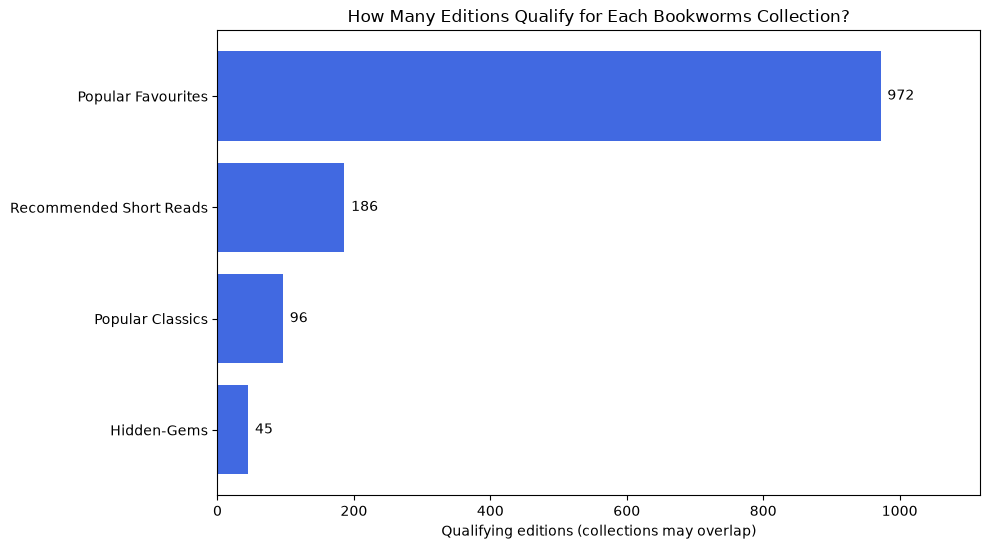

In [24]:
# Count the books that qualify for each collection
collection_names = ["Popular Favourites", "Recommended Short Reads", "Popular Classics", "Hidden-Gems"]

collection_counts = [popular_fav.sum(), short_reads.sum(), popular_classics.sum(), hidden_gems.sum()]

# Reverse the lists so Popular Favourites appears at the top
collection_names = collection_names[::-1]
collection_counts = collection_counts[::-1]

plt.figure(figsize=(10, 5.6))
plt.barh(collection_names, collection_counts, color="royalblue")

# Show the exact count beside each bar
for i, count in enumerate(collection_counts):
    plt.text(count + 10, i, f"{count:,}", va="center")

plt.title("How Many Editions Qualify for Each Bookworms Collection?")
plt.xlabel("Qualifying editions (collections may overlap)")
plt.xlim(0, max(collection_counts) * 1.15)
plt.tight_layout()

plt.savefig("bookworms_collections.png", dpi=200, bbox_inches="tight")
plt.show()